# 01 · Data exploration

Dataset: **UCI CDC Diabetes Health Indicators** (id 891, DOI 10.24432/C53919), derived from the CDC BRFSS 2015 telephone survey. 253,680 responses, 21 features, binary target `Diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes, self-reported).

EDA is run on the **training split only** so that no information from the test split influences modelling decisions.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.max_columns', 40)

In [2]:
from src.config import DATA_RAW, DATA_PROCESSED
print(json.dumps(json.loads((DATA_RAW/'PROVENANCE.json').read_text()), indent=2))

{
  "name": "CDC Diabetes Health Indicators",
  "uci_id": 891,
  "doi": "10.24432/C53919",
  "url": "https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators",
  "data_url": "https://archive.ics.uci.edu/static/public/891/data.csv",
  "metadata_api": "https://archive.ics.uci.edu/api/dataset?id=891",
  "license": "CC BY 4.0 (as listed on the UCI repository page \u2014 verify before redistribution)",
  "origin": "Derived from the CDC Behavioral Risk Factor Surveillance System (BRFSS) 2015 telephone survey",
  "file": "cdc_diabetes_health_indicators.csv",
  "sha256": "9f71fda9d4ae5f4878c99b9233b6a16accfa9a17c194116a6b78100540934964",
  "bytes": 13494568,
  "downloaded_at": "2026-11-16T12:42:46.713277+00:00"
}


In [3]:
raw = pd.read_csv(DATA_RAW/'cdc_diabetes_health_indicators.csv')
print(raw.shape)
raw.head()

(253680, 23)


,ID,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3
1,1,0,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1
2,2,0,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8
3,3,0,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6
4,4,0,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4


In [4]:
raw.dtypes.value_counts(), raw.isna().sum().sum()

(int64    23
 Name: count, dtype: int64,
 np.int64(0))

## Validation report
Schema, value domains (from the BRFSS data dictionary), duplicates and class balance.

In [5]:
print(json.dumps(json.loads((DATA_PROCESSED/'validation_report.json').read_text()), indent=2))

{
  "rows": 253680,
  "columns": 23,
  "missing_values": {},
  "duplicate_ids": 0,
  "duplicate_feature_rows": 24206,
  "out_of_domain": {},
  "non_integer_columns": [],
  "target_distribution": {
    "0": 218334,
    "1": 35346
  },
  "splits": {
    "train": {
      "rows": 152208,
      "positive_rate": 0.1393
    },
    "val": {
      "rows": 50736,
      "positive_rate": 0.1393
    },
    "test": {
      "rows": 50736,
      "positive_rate": 0.1393
    }
  }
}


## EDA (training split)

In [6]:
from src.evaluation import eda
report = eda.run()
pd.DataFrame(report['describe']).T

,count,mean,std,min,25%,50%,75%,max
HighBP,152208.0,0.430,0.495,0.0,0.0,0.0,1.0,1.0
HighChol,152208.0,0.424,0.494,0.0,0.0,0.0,1.0,1.0
CholCheck,152208.0,0.963,0.189,0.0,1.0,1.0,1.0,1.0
Smoker,152208.0,0.442,0.497,0.0,0.0,0.0,1.0,1.0
Stroke,152208.0,0.040,0.196,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,152208.0,0.094,0.292,0.0,0.0,0.0,0.0,1.0
PhysActivity,152208.0,0.757,0.429,0.0,1.0,1.0,1.0,1.0
Fruits,152208.0,0.634,0.482,0.0,0.0,1.0,1.0,1.0
Veggies,152208.0,0.811,0.392,0.0,1.0,1.0,1.0,1.0
HvyAlcoholConsump,152208.0,0.056,0.229,0.0,0.0,0.0,0.0,1.0


In [7]:
pd.Series(report['class_distribution'])

0    0.8607
1    0.1393
dtype: float64

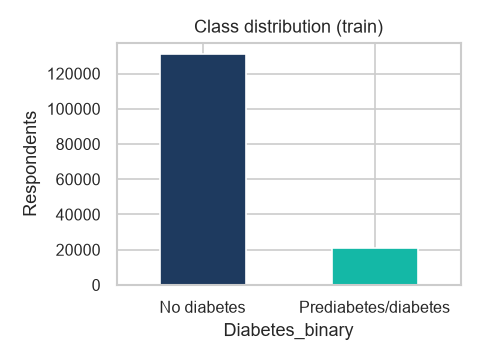

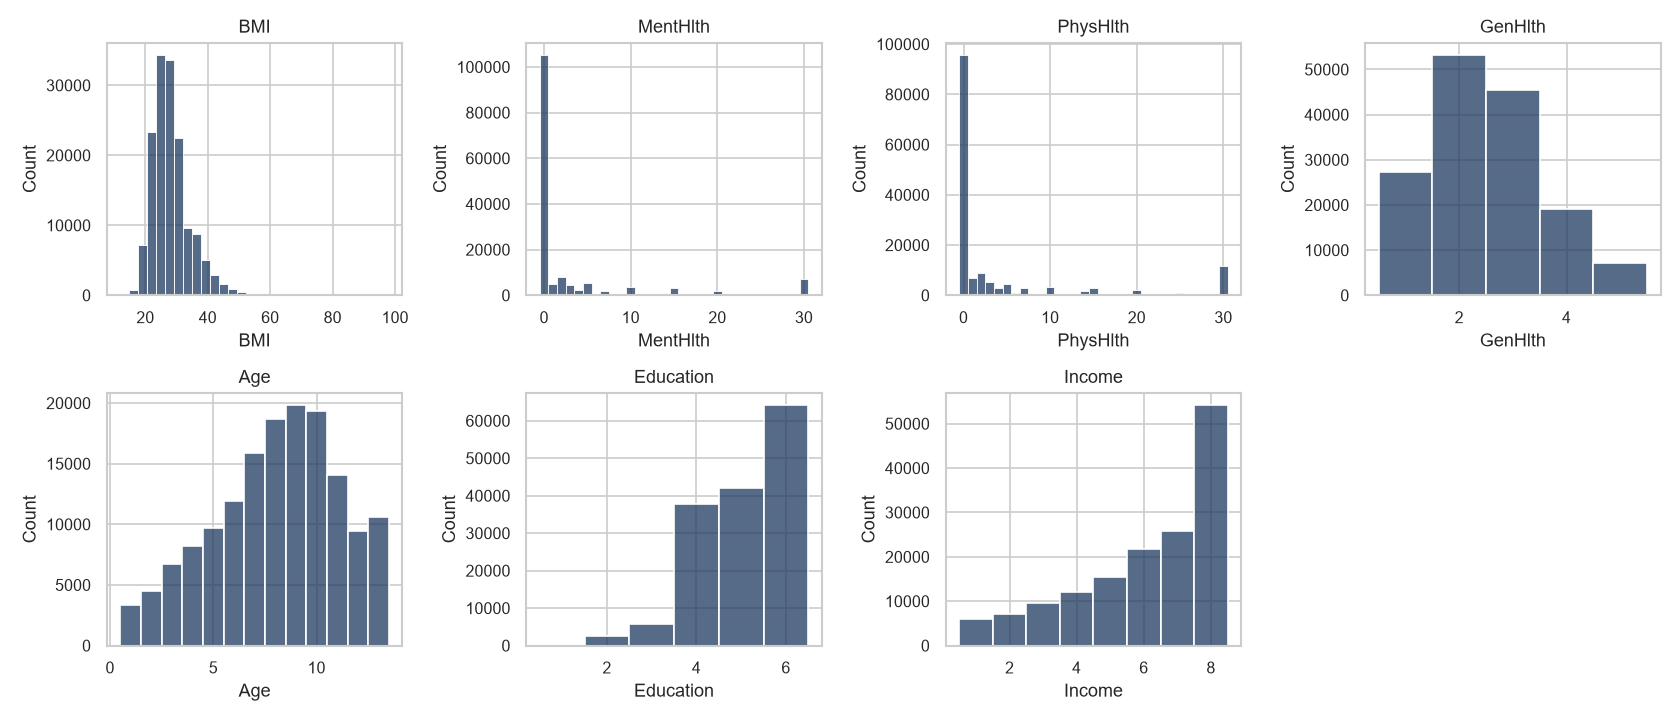

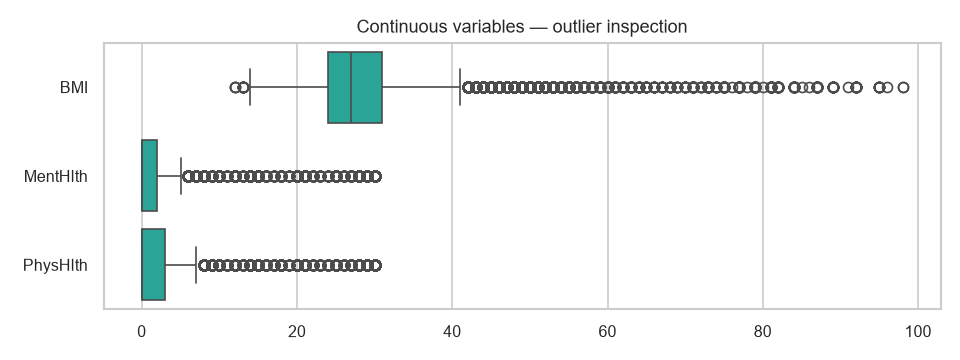

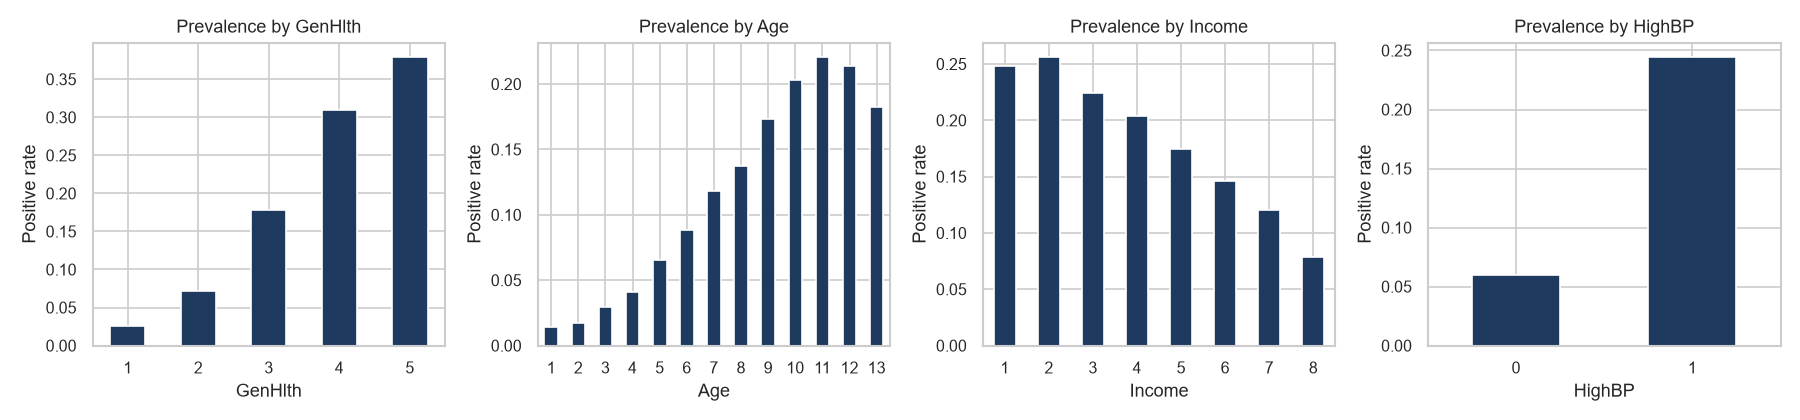

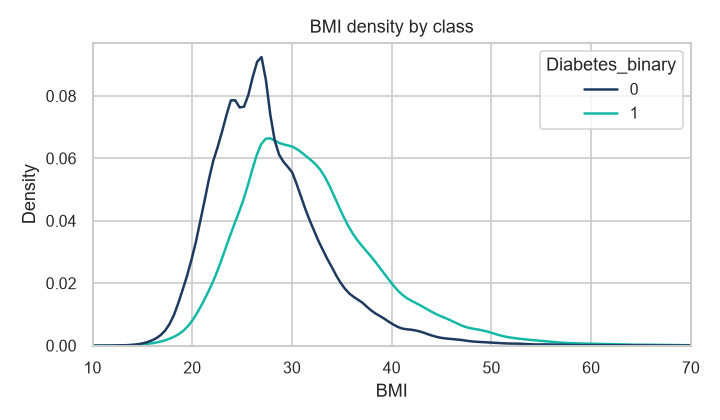

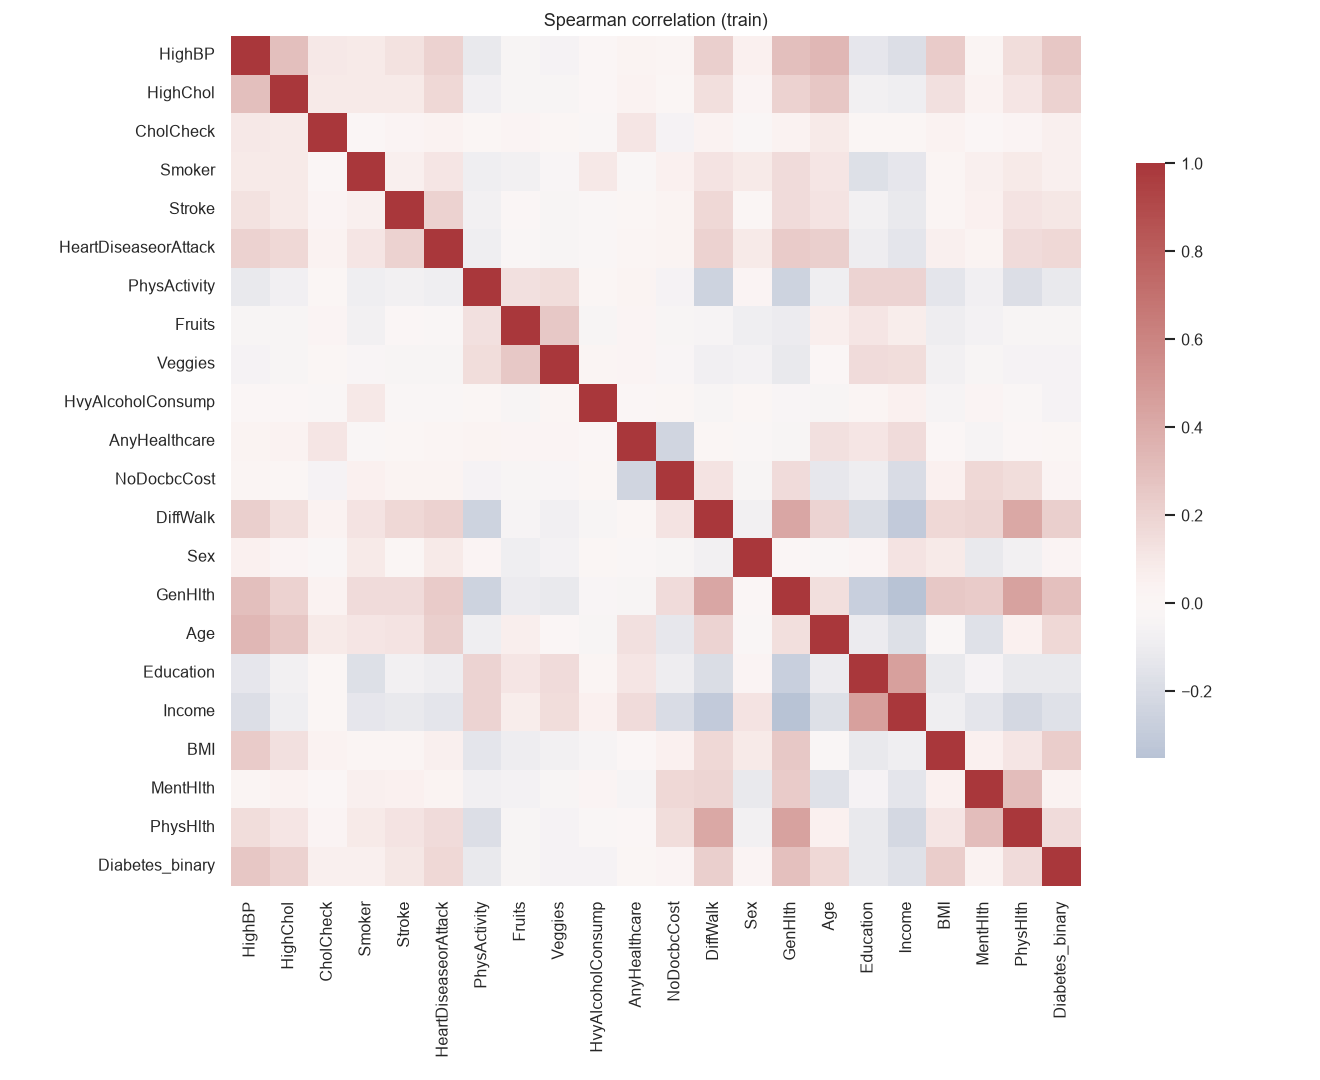

In [8]:
for f in ['class_distribution','univariate','outliers','prevalence_by_feature','bmi_by_class','correlation']:
    display(Image(filename=str(ROOT/'docs'/'figures'/f'eda_{f}.png')))

In [9]:
pd.DataFrame(report['outliers_iqr']).T

,iqr_low,iqr_high,n_outside,p99_9,max
BMI,13.5,41.5,5846.0,81.0,98.0
MentHlth,-3.0,5.0,21673.0,30.0,30.0
PhysHlth,-4.5,7.5,24607.0,30.0,30.0


`MentHlth` / `PhysHlth` are zero-inflated day counts (0–30), so the IQR rule flags many valid values. They are kept unchanged. BMI has a long right tail (max 98), so it is winsorised at training-set quantiles inside the pipeline.

In [10]:
assoc = pd.DataFrame(report['association_with_target']).T
assoc[['test','p_value','cramers_v','rank_biserial']].sort_values('p_value')

,test,p_value,cramers_v,rank_biserial
HighBP,chi2,0.0,0.2633,NaN
BMI,mann_whitney_u,0.0,NaN,0.3823
Income,chi2,0.0,0.1677,NaN
Education,chi2,0.0,0.1254,NaN
Age,chi2,0.0,0.1868,NaN
GenHlth,chi2,0.0,0.2994,NaN
DiffWalk,chi2,0.0,0.2203,NaN
PhysHlth,mann_whitney_u,0.0,NaN,0.2279
PhysActivity,chi2,0.0,0.1189,NaN
HeartDiseaseorAttack,chi2,0.0,0.1773,NaN


In [11]:
pd.Series(report['prevalence_by_bmi_category'])

underweight    0.0527
normal         0.0563
overweight     0.1126
obese_I        0.1945
obese_II       0.2746
obese_III      0.3397
dtype: float64

**Observations.** Self-rated general health, high blood pressure, BMI, walking difficulty, high cholesterol and age have the strongest associations with the target. Prevalence rises monotonically across BMI bands, which motivates the engineered `bmi_category` feature. Education and income are moderately correlated (ρ≈0.45), as are general health and physical-health days. With n≈150k almost every p-value is tiny, so the effect sizes matter more.